<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>



# **Final Project: Boston Housing**


##### Estimated time needed: **60** minutes


#### Import the required libraries we need for the lab.


In [2]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [3]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

<ipython-input-3-b3fdaf15785b>:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


#### Read the dataset in the csv file from the URL


In [4]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [5]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [11]:
# 1. Display the first 5 rows of the dataset
print(boston_df.head())

# 2. Display the data types of each column
print(boston_df.dtypes)

# 3. Check for missing values in each column
print(boston_df.isnull().sum())

# 4. Check for duplicate rows
print("Duplicate rows:", boston_df.duplicated().sum())

# 5. Display the correlation matrix of the dataset
print(boston_df.corr())

   Unnamed: 0     CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  \
0           0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0   
1           1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0   
2           2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0   
3           3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0   
4           4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0   

     TAX  PTRATIO  LSTAT  MEDV           age_group  
0  296.0     15.3   4.98  24.0   between 35 and 70  
1  242.0     17.8   9.14  21.6  70 years and older  
2  242.0     17.8   4.03  34.7   between 35 and 70  
3  222.0     18.7   2.94  33.4   between 35 and 70  
4  222.0     18.7   5.33  36.2   between 35 and 70  
Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           f

<class 'ValueError'>: could not convert string to float: 'between 35 and 70'

       Unnamed: 0        CRIM          ZN       INDUS        CHAS         NOX  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean   252.500000    3.613524   11.363636   11.136779    0.069170    0.554695   
std    146.213884    8.601545   23.322453    6.860353    0.253994    0.115878   
min      0.000000    0.006320    0.000000    0.460000    0.000000    0.385000   
25%    126.250000    0.082045    0.000000    5.190000    0.000000    0.449000   
50%    252.500000    0.256510    0.000000    9.690000    0.000000    0.538000   
75%    378.750000    3.677083   12.500000   18.100000    0.000000    0.624000   
max    505.000000   88.976200  100.000000   27.740000    1.000000    0.871000   

               RM         AGE         DIS         RAD         TAX     PTRATIO  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean     6.284634   68.574901    3.795043    9.549407  408.237154   18.455534   
std      0.702617   28.1488

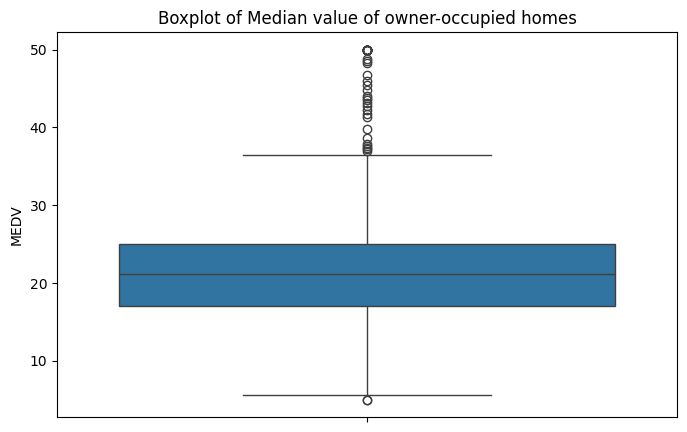

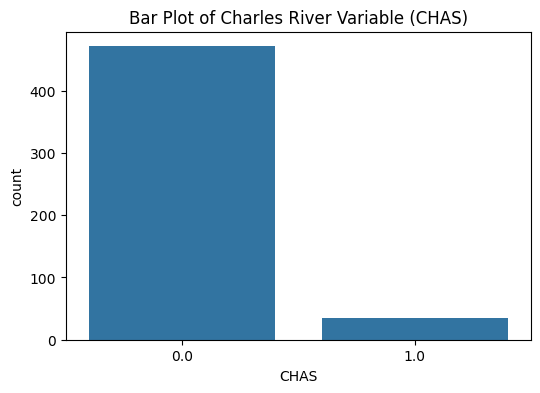

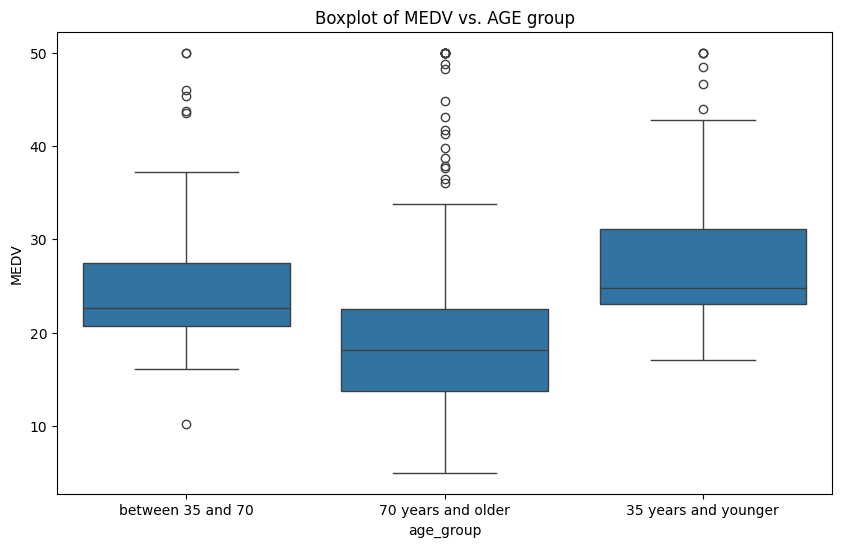

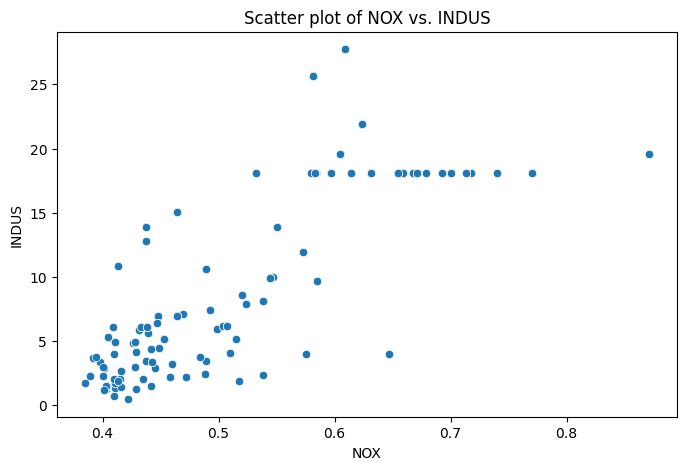

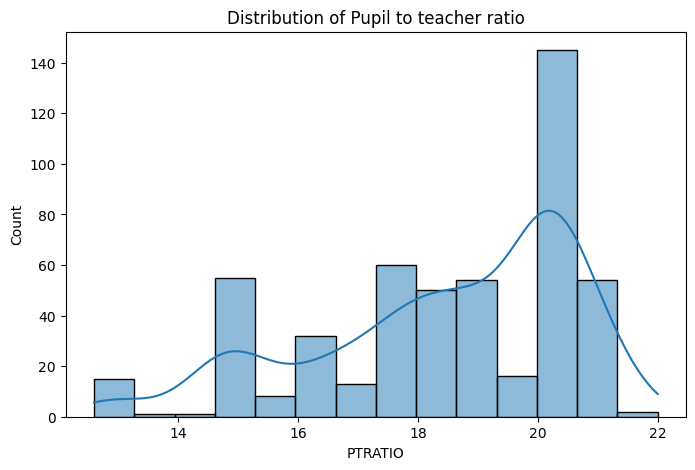

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Display descriptive statistics of the dataset
print(boston_df.describe())

# 2. Create a boxplot for MEDV
plt.figure(figsize=(8, 5))
sns.boxplot(y='MEDV', data=boston_df)
plt.title("Boxplot of Median value of owner-occupied homes")
plt.show()

# 3. Create a bar plot for CHAS
plt.figure(figsize=(6, 4))
sns.countplot(x='CHAS', data=boston_df)
plt.title("Bar Plot of Charles River Variable (CHAS)")
plt.show()

# 4. Discretize AGE into three groups and create a boxplot of MEDV versus these groups
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

plt.figure(figsize=(10, 6))
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
plt.title("Boxplot of MEDV vs. AGE group")
plt.show()

# 5. Create a scatter plot showing the relationship between NOX and INDUS
plt.figure(figsize=(8, 5))
sns.scatterplot(x='NOX', y='INDUS', data=boston_df)
plt.title("Scatter plot of NOX vs. INDUS")
plt.show()

# 6. Create a histogram for PTRATIO
plt.figure(figsize=(8, 5))
sns.histplot(boston_df['PTRATIO'], kde=True)
plt.title("Distribution of Pupil to teacher ratio")
plt.show()

In [8]:
import scipy.stats as stats
from statsmodels.formula.api import ols

# 1. Levene's test for MEDV by CHAS
chas_0 = boston_df[boston_df['CHAS'] == 0]['MEDV']
chas_1 = boston_df[boston_df['CHAS'] == 1]['MEDV']
levene_res = stats.levene(chas_0, chas_1)
print("Levene's test result:", levene_res)

# 2. T-test to determine if there is a significant difference in MEDV between homes bounded and not bounded by the Charles River
ttest_res = stats.ttest_ind(chas_0, chas_1, equal_var=False)
print("T-test result:", ttest_res)

# 3. ANOVA test to compare MEDV among the three AGE groups
f_val, p_val = stats.f_oneway(
    boston_df[boston_df['age_group'] == '35 years and younger']['MEDV'],
    boston_df[boston_df['age_group'] == 'between 35 and 70']['MEDV'],
    boston_df[boston_df['age_group'] == '70 years and older']['MEDV']
)
print(f"ANOVA F-value: {f_val}, p-value: {p_val}")

# 4. Pearson correlation test to assess the relationship between NOX and INDUS
pearson_res = stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])
print("Pearson correlation result:", pearson_res)

# 5. Fit a simple linear regression model to evaluate the impact of DIS on MEDV
model = ols('MEDV ~ DIS', data=boston_df).fit()
print(model.summary())

Levene's test result: LeveneResult(statistic=4.590342218715871, pvalue=0.03263097600633006)
T-test result: TtestResult(statistic=-3.113291312794837, pvalue=0.003567170098137517, df=36.876408797611994)
ANOVA F-value: 36.40764999196599, p-value: 1.7105011022702984e-15
Pearson correlation result: PearsonRResult(statistic=0.7636514469209192, pvalue=7.913361061210442e-98)
                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        09:26:02   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660